In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings('ignore')

In [2]:
FILE_PATH = r"D:\DOWNLOAD\Xiatang.csv"
OUTPUT_DIR = r"D:\DOWNLOAD"   

In [3]:
df = pd.read_csv(FILE_PATH)
df['time'] = pd.to_datetime(df['time'])
df = df.sort_values('time').reset_index(drop=True)
 
df['year']  = df['time'].dt.year
df['month'] = df['time'].dt.month
df['date']  = df['time'].dt.date

In [4]:
 
print("=" * 60)
print("XIATANG RIVER — WATER QUALITY ANALYSIS")
print("=" * 60)
print(f"\nShape       : {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Date range  : {df['time'].min().date()}  →  {df['time'].max().date()}")
print(f"\nColumns     : {list(df.columns)}")

XIATANG RIVER — WATER QUALITY ANALYSIS

Shape       : 6946 rows × 14 columns
Date range  : 2020-12-17  →  2025-12-05

Columns     : ['name', 'time', 'TEMP', 'pH', 'DO', 'EC', 'EUR', 'COMMn', 'NH3-N', 'TP', 'TN', 'year', 'month', 'date']


In [5]:
numeric_cols = ['TEMP', 'pH', 'DO', 'EC', 'EUR', 'COMMn', 'NH3-N', 'TP', 'TN']
 
print("\n── Descriptive Statistics ──────────────────────────────────")
print(df[numeric_cols].describe().round(3).to_string())
 
print("\n── Missing Values ──────────────────────────────────────────")
missing = df[numeric_cols].isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
miss_df = pd.DataFrame({'Missing': missing, 'Pct (%)': missing_pct})
print(miss_df[miss_df['Missing'] > 0].to_string())


── Descriptive Statistics ──────────────────────────────────
           TEMP        pH        DO        EC       EUR     COMMn     NH3-N        TP        TN
count  6896.000  6905.000  6904.000  6877.000  6876.000  6767.000  6892.000  6900.000  6861.000
mean      8.115     8.497    10.378   464.561    97.870     1.484     0.059     0.009     1.336
std       5.800     0.196     1.832    43.124   259.555     1.787     0.134     0.019     0.333
min       0.030     7.850     3.620     1.000     0.606     0.250     0.020     0.000     0.050
25%       1.700     8.370     9.117   435.000    15.686     0.747     0.025     0.005     1.182
50%       8.400     8.489    10.502   466.607    40.000     1.167     0.025     0.005     1.292
75%      13.516     8.690    11.749   498.698    96.000     1.605     0.048     0.009     1.432
max      23.034     8.940    14.170   535.160  9999.000    26.166     2.083     0.458     9.335

── Missing Values ──────────────────────────────────────────
       Missi

In [6]:
eur_outliers = df[df['EUR'] > 500]
print(f"\n── EUR Outliers (>500) ─────────────────────────────────────")
print(f"Count  : {len(eur_outliers)}")
print(f"Max    : {df['EUR'].max()}")
print("Likely sensor malfunctions — consider removing before modelling.")
 


── EUR Outliers (>500) ─────────────────────────────────────
Count  : 193
Max    : 9999.0
Likely sensor malfunctions — consider removing before modelling.


In [7]:
df['EUR_clean'] = df['EUR'].where(df['EUR'] <= 500, np.nan)

In [8]:
monthly = df.groupby('month')[numeric_cols].mean().round(3)
yearly  = df.groupby('year')[numeric_cols].mean().round(3)
 
print("\n── Monthly Averages ────────────────────────────────────────")
print(monthly[['TEMP', 'pH', 'DO', 'NH3-N', 'TP', 'TN']].to_string())
 
print("\n── Yearly Averages ─────────────────────────────────────────")
print(yearly[['TEMP', 'pH', 'DO', 'NH3-N', 'TP', 'TN']].to_string())
 


── Monthly Averages ────────────────────────────────────────
         TEMP     pH      DO  NH3-N     TP     TN
month                                            
1       1.109  8.406  11.919  0.051  0.011  1.440
2       0.948  8.445  11.862  0.076  0.009  1.422
3       3.611  8.476  11.901  0.050  0.007  1.280
4       8.666  8.549  10.301  0.075  0.012  1.413
5      11.455  8.538   9.722  0.083  0.009  1.289
6      13.958  8.534   9.151  0.051  0.008  1.210
7      15.910  8.543   8.955  0.089  0.018  1.395
8      16.137  8.528   8.469  0.059  0.011  1.373
9      13.815  8.544   9.133  0.066  0.010  1.412
10      9.240  8.559   9.893  0.058  0.007  1.237
11      4.399  8.443  10.778  0.040  0.008  1.309
12      1.239  8.423  11.762  0.028  0.005  1.327

── Yearly Averages ─────────────────────────────────────────
       TEMP     pH      DO  NH3-N     TP     TN
year                                           
2020  1.175  7.971  13.003  0.070  0.012  1.347
2021  7.058  8.337   9.817  0.06

In [9]:
corr = df[['TEMP', 'pH', 'DO', 'EC', 'NH3-N', 'TP', 'TN']].corr().round(3)
print("\n── Correlation Matrix ──────────────────────────────────────")
print(corr.to_string())


── Correlation Matrix ──────────────────────────────────────
        TEMP     pH     DO     EC  NH3-N     TP     TN
TEMP   1.000  0.237 -0.658 -0.153  0.073  0.101 -0.037
pH     0.237  1.000 -0.013  0.345 -0.029 -0.002 -0.085
DO    -0.658 -0.013  1.000 -0.211  0.032 -0.034  0.111
EC    -0.153  0.345 -0.211  1.000 -0.176 -0.012 -0.240
NH3-N  0.073 -0.029  0.032 -0.176  1.000  0.317  0.512
TP     0.101 -0.002 -0.034 -0.012  0.317  1.000  0.401
TN    -0.037 -0.085  0.111 -0.240  0.512  0.401  1.000


In [10]:
sns.set_theme(style="whitegrid", palette="muted")
MONTH_LABELS = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']


✓ Dashboard saved → D:\DOWNLOAD\xiatang_dashboard.png


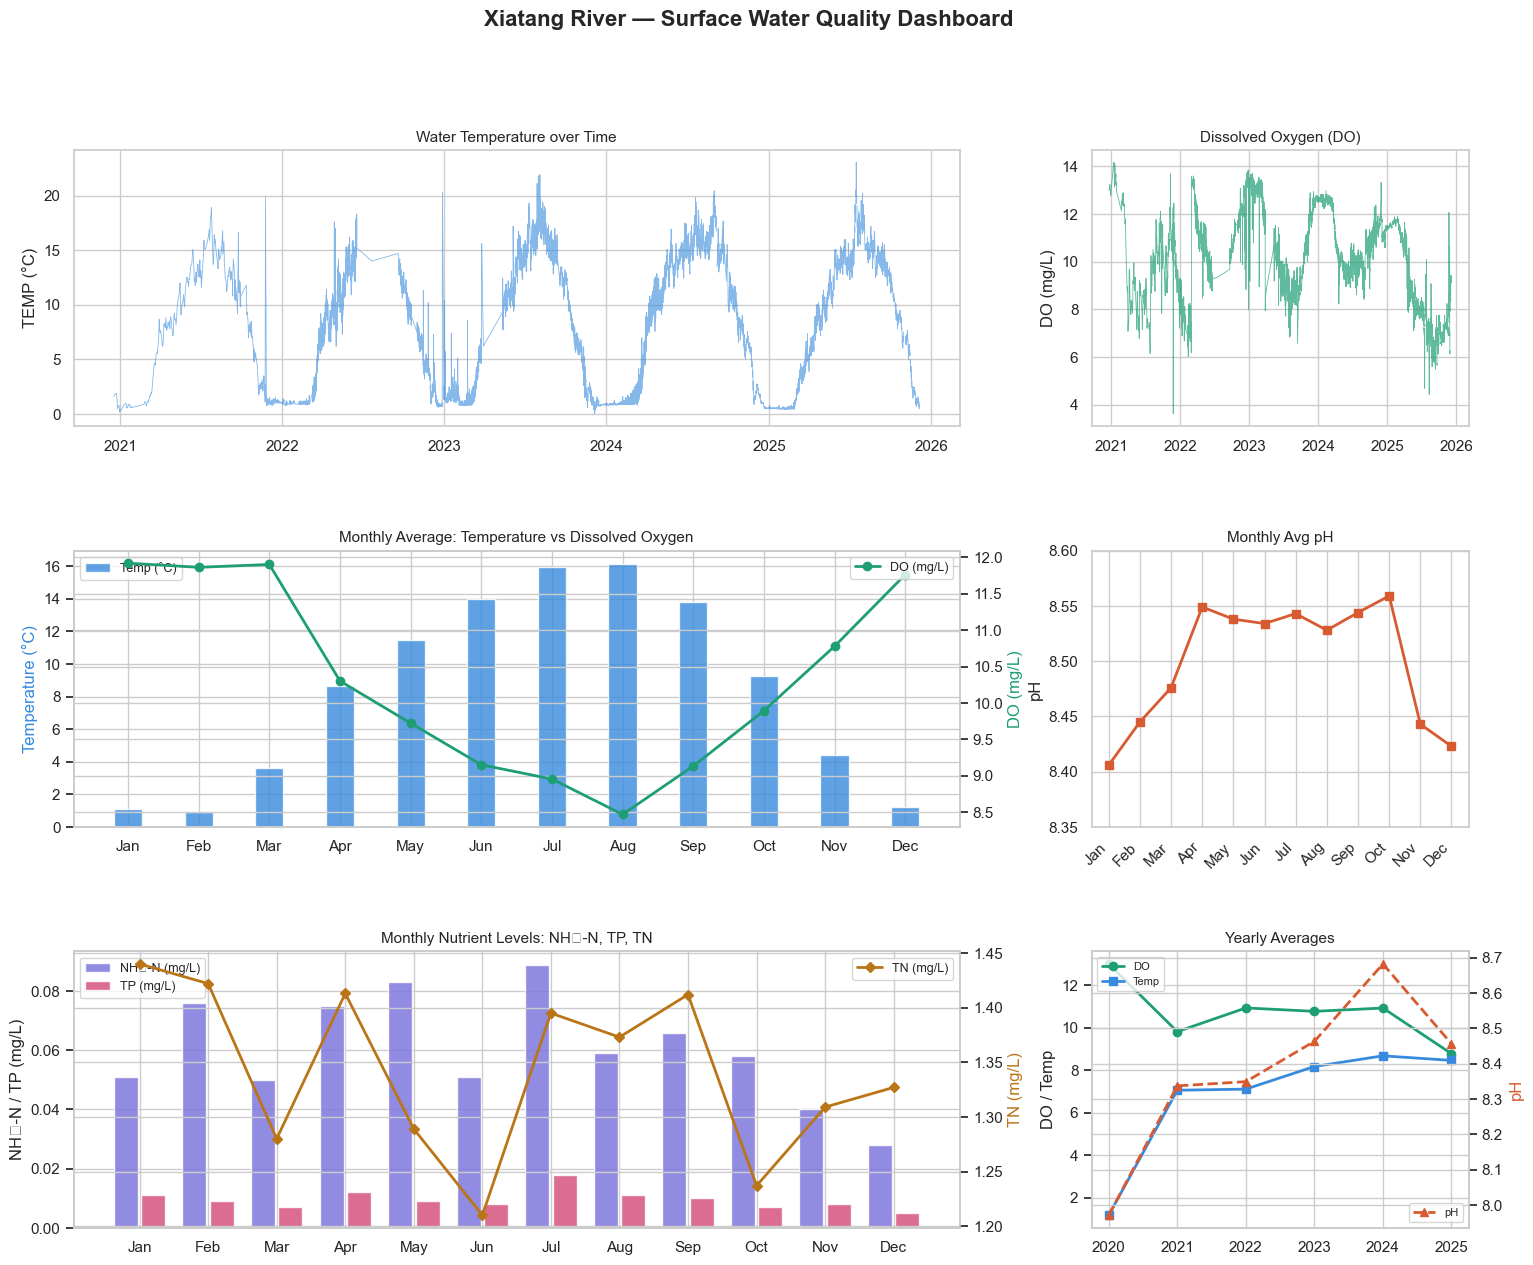

✓ Correlation heatmap saved → D:\DOWNLOAD\xiatang_correlation.png


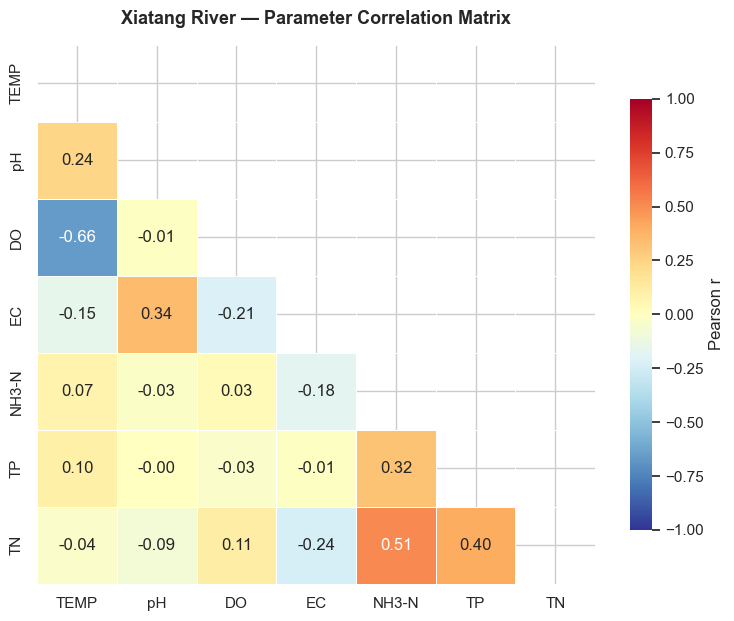

✓ Box plots saved → D:\DOWNLOAD\xiatang_boxplots.png


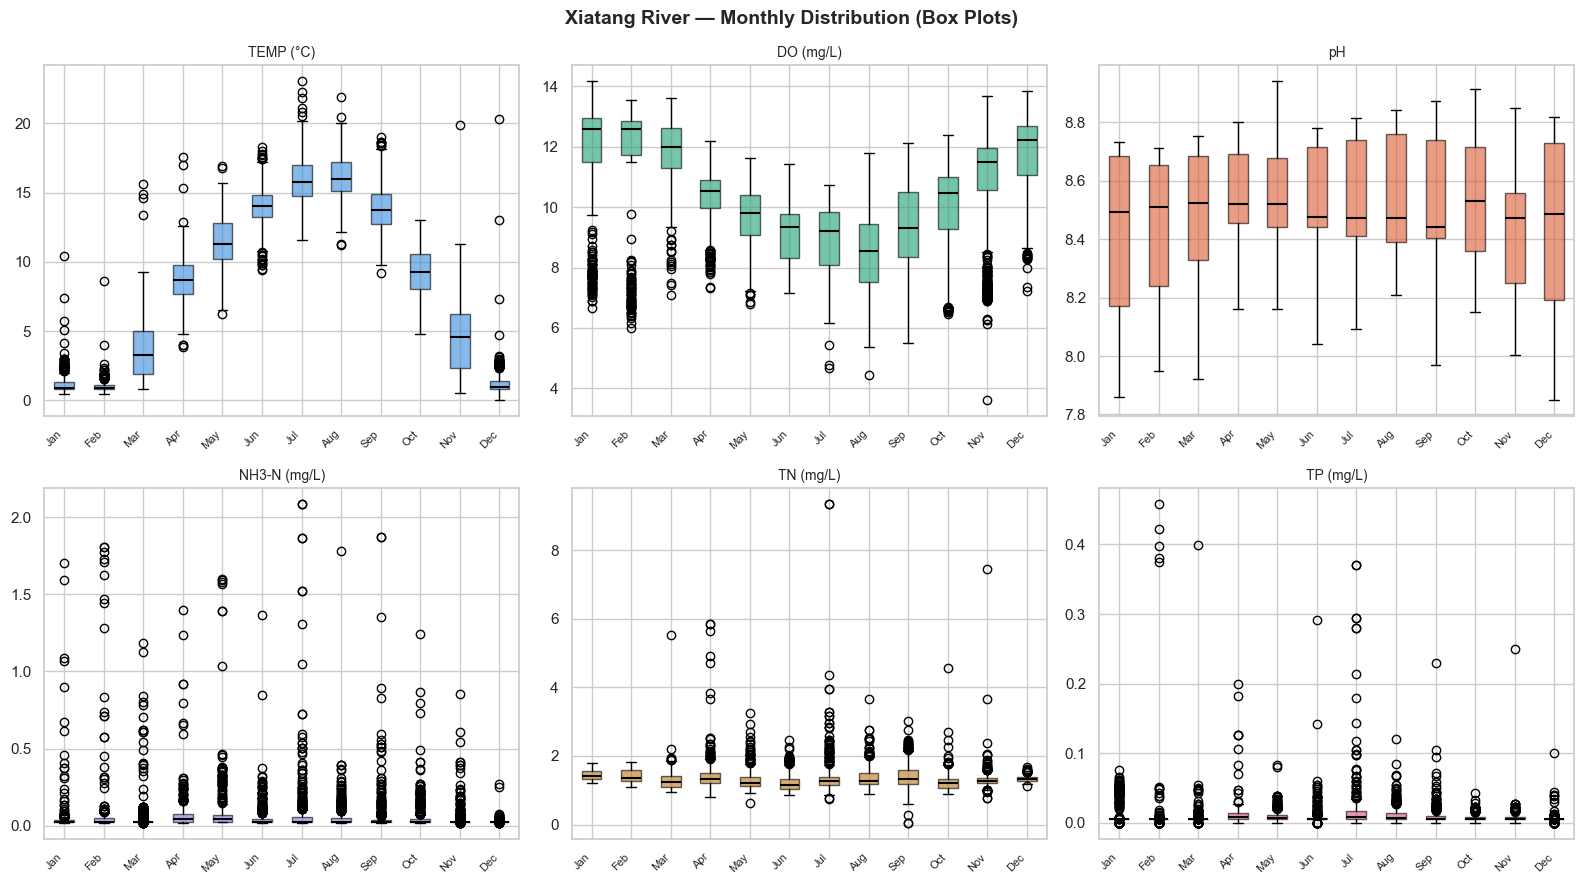

In [20]:
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Xiatang River — Surface Water Quality Dashboard", fontsize=16, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)
 
# 1a. Temperature time-series
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(df['time'], df['TEMP'], color='#378add', alpha=0.6, linewidth=0.6)
ax1.set_title('Water Temperature over Time', fontsize=11)
ax1.set_ylabel('TEMP (°C)')
ax1.set_xlabel('')
 
# 1b. DO time-series
ax2 = fig.add_subplot(gs[0, 2])
ax2.plot(df['time'], df['DO'], color='#1d9e75', alpha=0.7, linewidth=0.6)
ax2.set_title('Dissolved Oxygen (DO)', fontsize=11)
ax2.set_ylabel('DO (mg/L)')
ax3 = fig.add_subplot(gs[1, :2])
x = np.arange(12)
ax3.bar(x, monthly['TEMP'], color='#378add', alpha=0.8, label='Temp (°C)', width=0.4)
ax3b = ax3.twinx()
ax3b.plot(x, monthly['DO'], 'o-', color='#1d9e75', linewidth=2, markersize=6, label='DO (mg/L)')
ax3.set_xticks(x); ax3.set_xticklabels(MONTH_LABELS)
ax3.set_ylabel('Temperature (°C)', color='#378add')
ax3b.set_ylabel('DO (mg/L)', color='#1d9e75')
ax3.set_title('Monthly Average: Temperature vs Dissolved Oxygen', fontsize=11)
ax3.legend(loc='upper left', fontsize=9)
ax3b.legend(loc='upper right', fontsize=9)
 ##1d. pH monthly
ax4 = fig.add_subplot(gs[1, 2])
ax4.plot(x, monthly['pH'], 's-', color='#d85a30', linewidth=2, markersize=6)
ax4.set_xticks(x); ax4.set_xticklabels(MONTH_LABELS, rotation=45, ha='right')
ax4.set_ylabel('pH')
ax4.set_title('Monthly Avg pH', fontsize=11)
ax4.set_ylim(8.35, 8.60)
 
# 1e. Nutrients monthly
ax5 = fig.add_subplot(gs[2, :2])
ax5.bar(x - 0.2, monthly['NH3-N'], 0.35, color='#7f77dd', alpha=0.85, label='NH₃-N (mg/L)')
ax5.bar(x + 0.2, monthly['TP'],    0.35, color='#d4537e', alpha=0.85, label='TP (mg/L)')
ax5b = ax5.twinx()
ax5b.plot(x, monthly['TN'], 'D-', color='#ba7517', linewidth=2, markersize=5, label='TN (mg/L)')
ax5.set_xticks(x); ax5.set_xticklabels(MONTH_LABELS)
ax5.set_ylabel('NH₃-N / TP (mg/L)')
ax5b.set_ylabel('TN (mg/L)', color='#ba7517')
ax5.set_title('Monthly Nutrient Levels: NH₃-N, TP, TN', fontsize=11)
ax5.legend(loc='upper left', fontsize=9)
ax5b.legend(loc='upper right', fontsize=9)
 ##1f. Yearly trend
ax6 = fig.add_subplot(gs[2, 2])
yrs = yearly.index.astype(str)
ax6.plot(yrs, yearly['DO'],   'o-', color='#1d9e75', label='DO', linewidth=2)
ax6.plot(yrs, yearly['TEMP'], 's-', color='#378add', label='Temp', linewidth=2)
ax6b = ax6.twinx()
ax6b.plot(yrs, yearly['pH'], '^--', color='#d85a30', label='pH', linewidth=2)
ax6.set_ylabel('DO / Temp')
ax6b.set_ylabel('pH', color='#d85a30')
ax6.set_title('Yearly Averages', fontsize=11)
ax6.legend(loc='upper left', fontsize=8)
ax6b.legend(loc='lower right', fontsize=8)
plt.xticks(rotation=45)
 
path1 = rf"{OUTPUT_DIR}\xiatang_dashboard.png"
plt.savefig(path1, dpi=150, bbox_inches='tight')
print(f"\n✓ Dashboard saved → {path1}")
plt.show()
 
# ── Figure 2 : Correlation heatmap ───────────────────────────────────────────
fig2, ax = plt.subplots(figsize=(9, 7))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # upper triangle mask
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu_r',
    center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}
)
ax.set_title('Xiatang River — Parameter Correlation Matrix', fontsize=13, fontweight='bold', pad=15)
path2 = rf"{OUTPUT_DIR}\xiatang_correlation.png"
plt.savefig(path2, dpi=150, bbox_inches='tight')
print(f"✓ Correlation heatmap saved → {path2}")
plt.show()
 
# ── Figure 3 : Box plots — seasonal distribution ─────────────────────────────
fig3, axes = plt.subplots(2, 3, figsize=(16, 9))
fig3.suptitle('Xiatang River — Monthly Distribution (Box Plots)', fontsize=14, fontweight='bold')
 
params_box = [('TEMP', '°C', '#378add'), ('DO', 'mg/L', '#1d9e75'),
              ('pH', '', '#d85a30'), ('NH3-N', 'mg/L', '#7f77dd'),
              ('TN', 'mg/L', '#ba7517'), ('TP', 'mg/L', '#d4537e')]
 
for ax, (col, unit, color) in zip(axes.flat, params_box):
    data = [df[df['month'] == m][col].dropna().values for m in range(1, 13)]
    bp = ax.boxplot(data, patch_artist=True, medianprops=dict(color='black', linewidth=1.5))
    for patch in bp['boxes']:
        patch.set_facecolor(color); patch.set_alpha(0.6)
    ax.set_xticklabels(MONTH_LABELS, rotation=45, ha='right', fontsize=8)
    ax.set_title(f'{col} ({unit})' if unit else col, fontsize=10)
    ax.set_xlabel('')
 
plt.tight_layout()
path3 = rf"{OUTPUT_DIR}\xiatang_boxplots.png"
plt.savefig(path3, dpi=150, bbox_inches='tight')
print(f"✓ Box plots saved → {path3}")
plt.show()